Loaded binance and hyperliquid data from gcp data for both btc and pendle coins

this notebook will focus on modelling different latent state style approaches to modelling fair value

In [2]:
import pandas as pd
from pathlib import Path

In [4]:
# save data to a 'data' folder
DATA_ROOT = Path(
    r"C:\Users\markp\OneDrive\Documents\00GitHub\data\gcp\normalised"
)

In [9]:
def load_market_data(
    exchange,
    symbol,
    data_type="book",
    date=None,
):
    path = (
        DATA_ROOT
        / exchange.upper()
        / symbol.upper()
        / data_type
    )

    if date is not None:
        path = path / date

    if not path.exists():
        raise FileNotFoundError(
            f"No data found at:\n{path}"
        )

    df = pd.read_parquet(path)

    return df

In [10]:
hl_pendle = load_market_data(
    "HYPERLIQUID",
    "PENDLE-USD-PERP",
    "book"
)

binance_pendle = load_market_data(
    "BINANCE",
    "PENDLE-USDT",
    "book"
)

In [11]:
for df in [
    hl_pendle,
    binance_pendle,
]:

    df["datetime"] = pd.to_datetime(
        df["receipt_timestamp"],
        unit="s",
        utc=True
    )

In [12]:
hl_pendle = (
    hl_pendle
    .sort_values("datetime")
    .set_index("datetime")
)

binance_pendle = (
    binance_pendle
    .sort_values("datetime")
    .set_index("datetime")
)

In [14]:
from pathlib import Path

PROCESSED_ROOT = Path(
    r"C:\Users\markp\OneDrive\Documents\00GitHub\data\processed"
)

PROCESSED_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

### data management

In [24]:
binance_pendle_trades.to_parquet(
    pendle_dir / "binance_trades.parquet", 
    compression = "zstd"
) 

hp_pendle_trades.to_parquet(
    pendle_dir / "hype_trades.parquet", 
    compression = "zstd"
) 

In [21]:
hp_pendle_trades = pd.read_parquet(
    DATA_ROOT
    / "HYPERLIQUID"
    / "PENDLE-USD-PERP"
    / "trades"
    / "2026-09-28"
)


In [33]:
hp_pendle_books = pd.read_parquet(
    DATA_ROOT
    / "HYPERLIQUID"
    / "PENDLE-USD-PERP"
    / "book"
    / "2026-09-28"
)


In [7]:
binance_pendle_trades = pd.read_parquet(
    DATA_ROOT
    / "BINANCE"
    / "PENDLE-USDT"
    / "trades"
    / "2026-09-28"
)

binance_pendle_book = pd.read_parquet(
    DATA_ROOT
    / "BINANCE"
    / "PENDLE-USDT"
    / "book"
    / "2026-09-28"
)

In [8]:
binance_btc_book = pd.read_parquet(
    DATA_ROOT
    / "BINANCE"
    / "BTC-USDT"
    / "book"
    / "2026-09-28"
)

hl_btc_book = pd.read_parquet(
    DATA_ROOT
    / "HYPERLIQUID"
    / "BTC-USD-PERP"
    / "book"
    / "2026-09-28"
)

### analysis

In [27]:
binance_pendle_book.head()

,exchange,symbol,bid,bid_size,ask,ask_size,mid,spread,spread_bps,imbalance,microprice,exchange_timestamp,receipt_timestamp
0,BINANCE,PENDLE-USDT,2.44,533.7,2.441,423.0,2.4405,0.001,4.097521,0.11571,2.440558,NaN,1.790581e+09
1,BINANCE,PENDLE-USDT,2.44,533.7,2.441,423.0,2.4405,0.001,4.097521,0.11571,2.440558,1.790581e+09,1.790581e+09
2,BINANCE,PENDLE-USDT,2.44,533.7,2.441,423.0,2.4405,0.001,4.097521,0.11571,2.440558,1.790581e+09,1.790581e+09
3,BINANCE,PENDLE-USDT,2.44,533.7,2.441,423.0,2.4405,0.001,4.097521,0.11571,2.440558,1.790581e+09,1.790581e+09
4,BINANCE,PENDLE-USDT,2.44,533.7,2.441,423.0,2.4405,0.001,4.097521,0.11571,2.440558,1.790581e+09,1.790581e+09


In [28]:
binance_pendle_trades.head()

,exchange,symbol,side,price,amount,exchange_timestamp,receipt_timestamp
0,BINANCE,PENDLE-USDT,sell,2.441,61.5,1.790581e+09,1.790581e+09
1,BINANCE,PENDLE-USDT,sell,2.441,44.6,1.790581e+09,1.790581e+09
2,BINANCE,PENDLE-USDT,buy,2.442,6.2,1.790581e+09,1.790581e+09
3,BINANCE,PENDLE-USDT,buy,2.443,1.8,1.790581e+09,1.790581e+09
4,BINANCE,PENDLE-USDT,sell,2.441,15.0,1.790581e+09,1.790581e+09


In [29]:
hp_pendle_trades.head()

,exchange,symbol,side,price,amount,exchange_timestamp,receipt_timestamp
0,HYPERLIQUID,PENDLE-USD-PERP,sell,2.4437,654.0,1.790581e+09,1.790581e+09
1,HYPERLIQUID,PENDLE-USD-PERP,sell,2.4436,164.0,1.790581e+09,1.790581e+09
2,HYPERLIQUID,PENDLE-USD-PERP,sell,2.4436,276.0,1.790581e+09,1.790581e+09
3,HYPERLIQUID,PENDLE-USD-PERP,sell,2.4435,772.0,1.790581e+09,1.790581e+09
4,HYPERLIQUID,PENDLE-USD-PERP,sell,2.4435,277.0,1.790581e+09,1.790581e+09


In [34]:
hp_pendle_books.head()

,exchange,symbol,bid,bid_size,ask,ask_size,mid,spread,spread_bps,imbalance,microprice,exchange_timestamp,receipt_timestamp
0,HYPERLIQUID,PENDLE-USD-PERP,2.4409,458.0,2.4419,94.0,2.44140,0.0010,4.096010,0.659420,2.441730,1.790581e+09,1.790581e+09
1,HYPERLIQUID,PENDLE-USD-PERP,2.4410,654.0,2.4419,94.0,2.44145,0.0009,3.686334,0.748663,2.441787,1.790581e+09,1.790581e+09
2,HYPERLIQUID,PENDLE-USD-PERP,2.4426,654.0,2.4432,94.0,2.44290,0.0006,2.456097,0.748663,2.443125,1.790581e+09,1.790581e+09
3,HYPERLIQUID,PENDLE-USD-PERP,2.4424,654.0,2.4433,95.0,2.44285,0.0009,3.684221,0.746328,2.443186,1.790581e+09,1.790581e+09
4,HYPERLIQUID,PENDLE-USD-PERP,2.4430,654.0,2.4436,204.0,2.44330,0.0006,2.455695,0.524476,2.443457,1.790581e+09,1.790581e+09


In [35]:
b = binance_pendle_book.copy()

b["datetime"] = pd.to_datetime(
    b["receipt_timestamp"],
    unit="s",
    utc=True
)

b = (
    b
    .set_index("datetime")
    .sort_index()
)

h = hp_pendle_books.copy()

h["datetime"] = pd.to_datetime(
    h["receipt_timestamp"],
    unit="s",
    utc=True
)

h = (
    h
    .set_index("datetime")
    .sort_index()
)

In [57]:
b_10ms = (
    b[["mid"]]
    .resample("10ms")
    .last()
    .ffill()
    .rename(columns={"mid": "binance_mid"})
)

h_10ms = (
    h[["mid"]]
    .resample("10ms")
    .last()
    .ffill()
    .rename(columns={"mid": "hyperliquid_mid"})
)

df = b_10ms.join(
    h_10ms,
    how="inner"
)

is the 10ms the time it takes for cryptofeed to get the data, or the actual trading timestamps of the exchange?

In [60]:
df["mid_diff"] = (
    df["hyperliquid_mid"]
    - df["binance_mid"]
)

df["reference_mid"] = (
    df["hyperliquid_mid"]
    + df["binance_mid"]
) / 2

df["mid_diff_bps"] = (
    df["hyperliquid_mid"]
    - df["binance_mid"]
) / df["reference_mid"] * 10_000

<Axes: title={'center': 'Hyperliquid - Binance BTC Mid Difference (bps)'}, xlabel='datetime'>

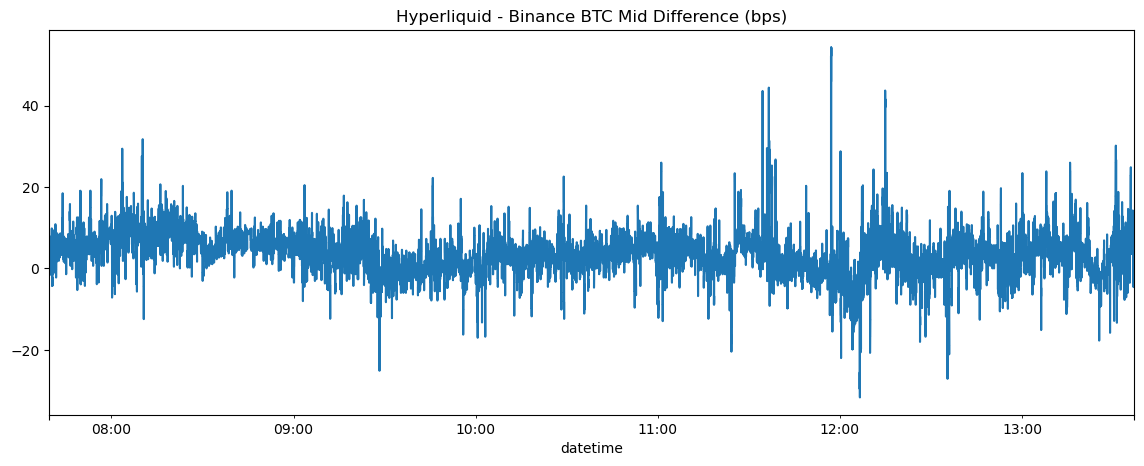

In [61]:
df["mid_diff_bps"].plot(
    figsize=(14, 5),
    title="Hyperliquid - Binance BTC Mid Difference (bps)"
)

<Axes: xlabel='datetime'>

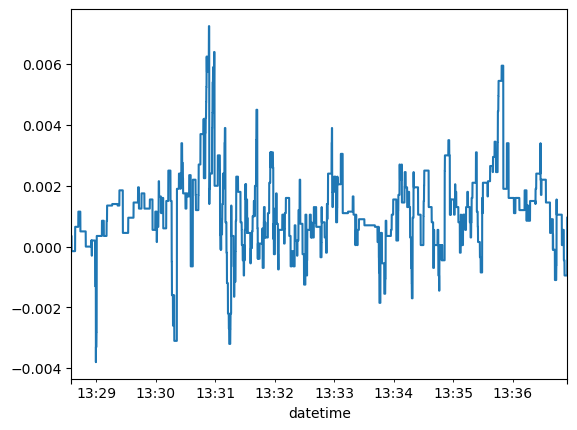

In [67]:
df['mid_diff'].iloc[-50_000:].plot()

### btc

In [25]:
hl_btc_book.head()

,exchange,symbol,bid,bid_size,ask,ask_size,mid,spread,spread_bps,imbalance,microprice,exchange_timestamp,receipt_timestamp
0,HYPERLIQUID,BTC-USD-PERP,82979.0,0.19943,82980.0,38.86387,82979.5,1.0,0.120512,-0.989789,82979.005105,1.790574e+09,1.790574e+09
1,HYPERLIQUID,BTC-USD-PERP,82979.0,0.19943,82980.0,38.86387,82979.5,1.0,0.120512,-0.989789,82979.005105,1.790574e+09,1.790574e+09
2,HYPERLIQUID,BTC-USD-PERP,82967.0,1.48676,82968.0,8.60981,82967.5,1.0,0.120529,-0.705492,82967.147254,1.790574e+09,1.790574e+09
3,HYPERLIQUID,BTC-USD-PERP,82955.0,3.37599,82956.0,10.31413,82955.5,1.0,0.120547,-0.506799,82955.246600,1.790574e+09,1.790574e+09
4,HYPERLIQUID,BTC-USD-PERP,82955.0,0.52253,82956.0,27.98517,82955.5,1.0,0.120547,-0.963341,82955.018329,1.790574e+09,1.790574e+09


In [26]:
binance_btc_book.head()

,exchange,symbol,bid,bid_size,ask,ask_size,mid,spread,spread_bps,imbalance,microprice,exchange_timestamp,receipt_timestamp
0,BINANCE,BTC-USDT,83083.75,6.67238,83083.76,6.58719,83083.755,0.01,0.001204,0.006425,83083.755032,NaN,1.790573e+09
1,BINANCE,BTC-USDT,83083.75,6.67354,83083.76,5.33761,83083.755,0.01,0.001204,0.111224,83083.755556,1.790573e+09,1.790573e+09
2,BINANCE,BTC-USDT,83083.75,4.06993,83083.76,7.19325,83083.755,0.01,0.001204,-0.277304,83083.753613,1.790573e+09,1.790573e+09
3,BINANCE,BTC-USDT,83083.75,2.82015,83083.76,6.94836,83083.755,0.01,0.001204,-0.422604,83083.752887,1.790573e+09,1.790573e+09
4,BINANCE,BTC-USDT,83083.75,2.82012,83083.76,7.38183,83083.755,0.01,0.001204,-0.447141,83083.752764,1.790573e+09,1.790573e+09
